# Notebook 08 — Advanced Ensemble Optimization, Cost-Sensitive Learning and Explainability

**Project:** ECIPS — leakage-resistant risk classification using the Kaggle Metaverse Financial Transactions dataset.

## Purpose

This notebook extends Notebook 07 without changing its conservative feature policy. It compares candidate models under one consistent chronological split, evaluates class-weighting and high-risk screening thresholds using validation data only, and reports explainability and error analysis.

## Important interpretation limits

- The target is the dataset's **Kaggle-provided risk label**, not independently verified fraud ground truth.
- `risk_score`, `transaction_type`, `age_group`, `purchase_pattern`, sender/receiver addresses, and raw `timestamp` remain excluded from model inputs.
- `hour_of_day` is retained as a derived time feature; it is not independent of `timestamp`.
- Predictive importance is not causal importance and does not establish feature provenance.
- The final test set is opened only after model and threshold selection are complete.
- High recall can create many false positives. Thresholds are screening scenarios, not automatic transaction-blocking rules.
- Default cost weights below are **illustrative assumptions**, not empirically established business costs. Replace them with stakeholder-approved costs before operational use.

## Expected source file

Upload `metaverse_transactions_dataset.csv` to the Colab session, or update `DATA_PATH` below.

In [20]:
# 1. Environment and configuration
from pathlib import Path
import json, hashlib, warnings, sys, subprocess, importlib.util
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, balanced_accuracy_score, classification_report,
    confusion_matrix, f1_score, precision_score, recall_score,
    average_precision_score, roc_auc_score, precision_recall_curve
)
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler, label_binarize
from sklearn.inspection import permutation_importance

RANDOM_STATE = 42
DATA_PATH = Path("/content/metaverse_transactions_dataset.csv")
OUTPUT_DIR = Path("/content/ecips_notebook08_outputs")
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

# Fixed chronological split proportions — same design as Notebook 07.
TRAIN_FRAC = 0.70
VALIDATION_FRAC = 0.10
TEST_FRAC = 0.20

# Screening target. The threshold is chosen on validation only.
HIGH_RISK_LABEL = "high_risk"
MIN_VALIDATION_HIGH_RISK_RECALL = 0.80

# Illustrative cost assumptions, expressed in relative units.
# A missed high-risk case is assigned a higher cost than a false alert.
COST_FALSE_NEGATIVE_HIGH = 10.0
COST_FALSE_POSITIVE_HIGH = 1.0

print("Python:", sys.version)
print("Output directory:", OUTPUT_DIR)

Python: 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]
Output directory: /content/ecips_notebook08_outputs


## 2. Load data and verify source integrity

The notebook checks the file hash and expected schema. If the dataset has changed, stop and reconcile the source before comparing results with earlier notebooks.

In [21]:
if not DATA_PATH.exists():
    raise FileNotFoundError(
        f"Dataset not found at {DATA_PATH}. Upload the CSV and update DATA_PATH."
    )

df = pd.read_csv(DATA_PATH)
sha256 = hashlib.sha256(DATA_PATH.read_bytes()).hexdigest()

EXPECTED_SHA256 = "c7eae68df7ff627089b44df6123c4974e71065f4c342b45a4bf4664bdea6beb0"
print("Shape:", df.shape)
print("SHA-256:", sha256)
print("Expected hash:", EXPECTED_SHA256)
print("Hash matches expected source:", sha256 == EXPECTED_SHA256)

required = {
    "timestamp", "amount", "hour_of_day", "login_frequency",
    "session_duration", "location_region", "ip_prefix", "anomaly"
}
missing = required - set(df.columns)
if missing:
    raise ValueError(f"Missing required columns: {sorted(missing)}")

if sha256 != EXPECTED_SHA256:
    raise ValueError("Source hash differs from the previously audited source. Verify before proceeding.")

print("\nTarget distribution:")
display(df["anomaly"].value_counts(dropna=False).rename("count").to_frame())

Shape: (78600, 14)
SHA-256: c7eae68df7ff627089b44df6123c4974e71065f4c342b45a4bf4664bdea6beb0
Expected hash: c7eae68df7ff627089b44df6123c4974e71065f4c342b45a4bf4664bdea6beb0
Hash matches expected source: True

Target distribution:


,count
anomaly,
low_risk,63494
moderate_risk,8611
high_risk,6495


## 3. Chronological split and conservative feature set

Rows are sorted by `timestamp`; the first 70% are training, the next 10% validation, and the final 20% test. The feature list intentionally excludes known or suspected target proxies.

In [22]:
df = df.copy()
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
if df["timestamp"].isna().any():
    raise ValueError("Invalid timestamps found. Resolve before chronological splitting.")

df = df.sort_values("timestamp", kind="mergesort").reset_index(drop=True)

FEATURES_NUMERIC = [
    "amount", "hour_of_day", "login_frequency", "session_duration", "ip_prefix"
]
FEATURES_CATEGORICAL = ["location_region"]
FEATURES = FEATURES_NUMERIC + FEATURES_CATEGORICAL
TARGET = "anomaly"

# Explicit exclusion guardrail
PROHIBITED = {
    "risk_score", "transaction_type", "age_group", "purchase_pattern",
    "sending_address", "receiving_address", "timestamp", TARGET
}
assert not (set(FEATURES) & PROHIBITED)

n = len(df)
train_end = int(n * TRAIN_FRAC)
val_end = int(n * (TRAIN_FRAC + VALIDATION_FRAC))

train_df = df.iloc[:train_end].copy()
val_df = df.iloc[train_end:val_end].copy()
test_df = df.iloc[val_end:].copy()

X_train, y_train = train_df[FEATURES], train_df[TARGET]
X_val, y_val = val_df[FEATURES], val_df[TARGET]
X_test, y_test = test_df[FEATURES], test_df[TARGET]

LABELS = sorted(y_train.unique().tolist())
if set(y_val.unique()) - set(LABELS) or set(y_test.unique()) - set(LABELS):
    raise ValueError("A class appears only after training; revise split or class handling.")

print("Rows:", {"train": len(train_df), "validation": len(val_df), "test": len(test_df)})
print("Classes:", LABELS)
display(pd.DataFrame({
    "train": y_train.value_counts(normalize=True),
    "validation": y_val.value_counts(normalize=True),
    "test": y_test.value_counts(normalize=True)
}).fillna(0))

Rows: {'train': 55020, 'validation': 7859, 'test': 15721}
Classes: ['high_risk', 'low_risk', 'moderate_risk']


,train,validation,test
anomaly,,,
low_risk,0.806343,0.812699,0.810508
moderate_risk,0.109960,0.108029,0.108899
high_risk,0.083697,0.079272,0.080593


## 4. Preprocessing and candidate models

All candidates use the same input features, split, and validation metrics. LightGBM and XGBoost are included when installed; optional installation is available below. The selection rule is pre-specified: maximize validation macro-F1, then balanced accuracy, then high-risk recall.

In [23]:
numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])
preprocessor = ColumnTransformer([
    ("num", numeric_pipe, FEATURES_NUMERIC),
    ("cat", categorical_pipe, FEATURES_CATEGORICAL)
])

def make_pipeline(model):
    return Pipeline([("prep", clone(preprocessor)), ("model", model)])

models = {
    "RandomForest": RandomForestClassifier(
        n_estimators=500, min_samples_leaf=2, class_weight=None,
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "RandomForest_balanced": RandomForestClassifier(
        n_estimators=500, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "ExtraTrees_balanced": ExtraTreesClassifier(
        n_estimators=500, min_samples_leaf=2, class_weight="balanced",
        random_state=RANDOM_STATE, n_jobs=-1
    ),
    "LogisticRegression_balanced": LogisticRegression(
        max_iter=3000, class_weight="balanced", C=1.0,
        random_state=RANDOM_STATE
    )
}

# Optional gradient boosting candidates, only if libraries are already available.
if importlib.util.find_spec("lightgbm"):
    from lightgbm import LGBMClassifier
    models["LightGBM"] = LGBMClassifier(
        n_estimators=500, learning_rate=0.04, num_leaves=31,
        class_weight="balanced", random_state=RANDOM_STATE, verbosity=-1
    )
else:
    print("LightGBM not installed — candidate skipped.")

if importlib.util.find_spec("xgboost"):
    from xgboost import XGBClassifier
    # Multi-class objective; no scale_pos_weight for multi-class.
    models["XGBoost"] = XGBClassifier(
        n_estimators=400, max_depth=5, learning_rate=0.04,
        subsample=0.85, colsample_bytree=0.85,
        objective="multi:softprob", eval_metric="mlogloss",
        random_state=RANDOM_STATE, n_jobs=-1
    )
else:
    print("XGBoost not installed — candidate skipped.")

print("Candidates:", list(models))

Candidates: ['RandomForest', 'RandomForest_balanced', 'ExtraTrees_balanced', 'LogisticRegression_balanced', 'LightGBM', 'XGBoost']


In [24]:
# Fit and score every candidate on the same validation partition.
from sklearn.preprocessing import LabelEncoder

validation_rows = []
fitted_models = {}
validation_probabilities = {}

# Fit a single label encoder for target variables
le = LabelEncoder()
y_train_encoded = le.fit_transform(y_train)
y_val_encoded = le.transform(y_val)

for name, estimator in models.items():
    pipe = make_pipeline(estimator)

    # XGBoost requires integer targets for multiclass
    if name == "XGBoost":
        pipe.fit(X_train, y_train_encoded)
        pred_encoded = pipe.predict(X_val)
        pred = le.inverse_transform(pred_encoded)
        proba = pipe.predict_proba(X_val)
    else:
        pipe.fit(X_train, y_train)
        pred = pipe.predict(X_val)
        proba = pipe.predict_proba(X_val)

    fitted_models[name] = pipe
    validation_probabilities[name] = proba

    high_idx = list(pipe.classes_).index(HIGH_RISK_LABEL) if name != "XGBoost" else list(le.classes_).index(HIGH_RISK_LABEL)
    high_truth = (y_val == HIGH_RISK_LABEL).astype(int)
    high_pred = (pred == HIGH_RISK_LABEL).astype(int)

    validation_rows.append({
        "model": name,
        "accuracy": accuracy_score(y_val, pred),
        "balanced_accuracy": balanced_accuracy_score(y_val, pred),
        "macro_precision": precision_score(y_val, pred, average="macro", zero_division=0),
        "macro_recall": recall_score(y_val, pred, average="macro", zero_division=0),
        "macro_f1": f1_score(y_val, pred, average="macro", zero_division=0),
        "weighted_f1": f1_score(y_val, pred, average="weighted", zero_division=0),
        "high_risk_precision_argmax": precision_score(high_truth, high_pred, zero_division=0),
        "high_risk_recall_argmax": recall_score(high_truth, high_pred, zero_division=0),
        "high_risk_average_precision": average_precision_score(high_truth, proba[:, high_idx])
    })

# Ensure selected model wrapper can handle prediction transparently if it is XGBoost
class XGBoostLabelWrapper:
    def __init__(self, pipeline, label_encoder):
        self.pipeline = pipeline
        self.le = label_encoder
        self.classes_ = label_encoder.classes_

    def predict(self, X):
        preds_encoded = self.pipeline.predict(X)
        return self.le.inverse_transform(preds_encoded)

    def predict_proba(self, X):
        return self.pipeline.predict_proba(X)

validation_results = pd.DataFrame(validation_rows).sort_values(
    ["macro_f1", "balanced_accuracy", "high_risk_recall_argmax"],
    ascending=False
).reset_index(drop=True)

display(validation_results)
validation_results.to_csv(OUTPUT_DIR / "08_validation_model_comparison.csv", index=False)

selected_name = validation_results.iloc[0]["model"]
selected_model = fitted_models[selected_name]
if selected_name == "XGBoost":
    selected_model = XGBoostLabelWrapper(selected_model, le)

print("Selected model under pre-specified rule:", selected_name)

/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(


,model,accuracy,balanced_accuracy,macro_precision,macro_recall,macro_f1,weighted_f1,high_risk_precision_argmax,high_risk_recall_argmax,high_risk_average_precision
0,ExtraTrees_balanced,0.772745,0.795413,0.635079,0.795413,0.672648,0.804282,0.261108,0.688604,0.267835
1,LightGBM,0.725410,0.851516,0.640847,0.851516,0.664424,0.769652,0.247834,0.918138,0.253506
2,RandomForest_balanced,0.847309,0.687243,0.632713,0.687243,0.651536,0.843120,0.288747,0.218299,0.269559
3,RandomForest,0.865123,0.625998,0.617853,0.625998,0.587565,0.836692,0.253521,0.028892,0.267919
4,XGBoost,0.871358,0.629538,0.601122,0.629538,0.576903,0.837348,0.200000,0.001605,0.252372
5,LogisticRegression_balanced,0.615473,0.797340,0.543002,0.797340,0.549353,0.660558,0.247068,0.980738,0.251527


Selected model under pre-specified rule: ExtraTrees_balanced


## 5. Cost-sensitive high-risk threshold selection

This section treats high-risk detection as a one-vs-rest screening task. It selects a threshold using validation probabilities only. First, it finds thresholds meeting the minimum validation recall constraint; among those, it minimizes the illustrative validation cost. If no threshold meets the constraint, it selects the threshold with the highest recall and reports that the constraint was infeasible.

The cost calculation is:

`cost = false_negatives × FN_cost + false_positives × FP_cost`

This is a scenario analysis, not a validated operational loss model.

Selected threshold: 0.22282828282828282
Validation recall constraint met: True
Validation operating point:


,value
threshold,0.222828
tp,622.000000
fp,1917.000000
fn,1.000000
tn,5319.000000
precision,0.244978
recall,0.998395
f1,0.393422
illustrative_cost,1927.000000


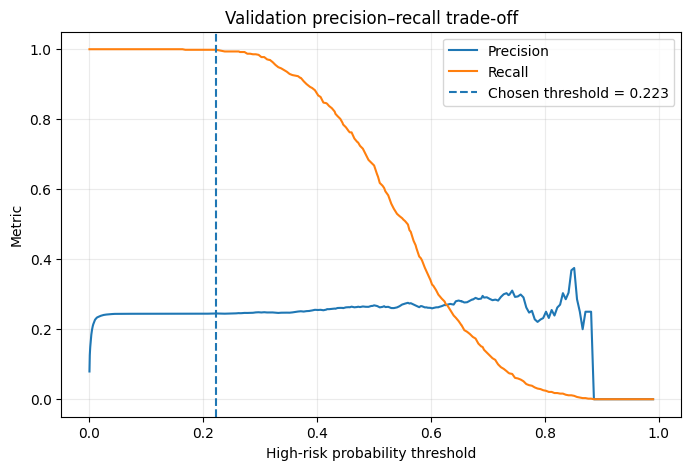

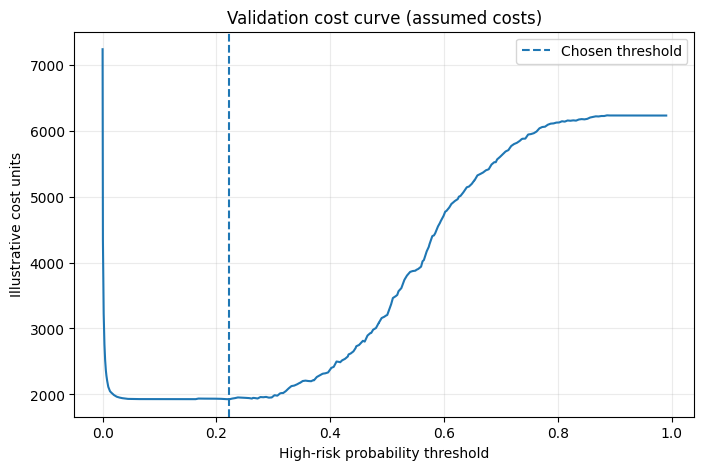

In [25]:
classes = list(selected_model.classes_)
high_idx = classes.index(HIGH_RISK_LABEL)
val_high_true = (y_val == HIGH_RISK_LABEL).astype(int).to_numpy()
val_high_score = selected_model.predict_proba(X_val)[:, high_idx]

threshold_grid = np.unique(np.r_[
    np.linspace(0.01, 0.99, 199),
    np.quantile(val_high_score, np.linspace(0, 1, 101))
])

threshold_rows = []
for threshold in threshold_grid:
    pred_high = (val_high_score >= threshold).astype(int)
    tp = int(((pred_high == 1) & (val_high_true == 1)).sum())
    fp = int(((pred_high == 1) & (val_high_true == 0)).sum())
    fn = int(((pred_high == 0) & (val_high_true == 1)).sum())
    tn = int(((pred_high == 0) & (val_high_true == 0)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    cost = fn * COST_FALSE_NEGATIVE_HIGH + fp * COST_FALSE_POSITIVE_HIGH
    threshold_rows.append({
        "threshold": float(threshold), "tp": tp, "fp": fp, "fn": fn, "tn": tn,
        "precision": precision, "recall": recall, "f1": f1, "illustrative_cost": cost
    })

threshold_results = pd.DataFrame(threshold_rows).drop_duplicates("threshold")
feasible = threshold_results[
    threshold_results["recall"] >= MIN_VALIDATION_HIGH_RISK_RECALL
]
if len(feasible):
    chosen_threshold_row = feasible.sort_values(
        ["illustrative_cost", "f1"], ascending=[True, False]
    ).iloc[0]
    constraint_met = True
else:
    chosen_threshold_row = threshold_results.sort_values(
        ["recall", "illustrative_cost"], ascending=[False, True]
    ).iloc[0]
    constraint_met = False

chosen_threshold = float(chosen_threshold_row["threshold"])
print("Selected threshold:", chosen_threshold)
print("Validation recall constraint met:", constraint_met)
print("Validation operating point:")
display(chosen_threshold_row.to_frame("value"))

threshold_results.to_csv(OUTPUT_DIR / "08_validation_high_risk_threshold_curve.csv", index=False)

plt.figure(figsize=(8, 5))
plt.plot(threshold_results["threshold"], threshold_results["precision"], label="Precision")
plt.plot(threshold_results["threshold"], threshold_results["recall"], label="Recall")
plt.axvline(chosen_threshold, linestyle="--", label=f"Chosen threshold = {chosen_threshold:.3f}")
plt.xlabel("High-risk probability threshold")
plt.ylabel("Metric")
plt.title("Validation precision–recall trade-off")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

plt.figure(figsize=(8, 5))
plt.plot(threshold_results["threshold"], threshold_results["illustrative_cost"])
plt.axvline(chosen_threshold, linestyle="--", label="Chosen threshold")
plt.xlabel("High-risk probability threshold")
plt.ylabel("Illustrative cost units")
plt.title("Validation cost curve (assumed costs)")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

## 6. One-time final test evaluation

The selected model and high-risk threshold are now frozen. Do not change them based on test results. The standard multiclass prediction uses the model's argmax class; the high-risk screening result is reported separately because it is a one-vs-rest alert rule.

In [26]:
# Final multiclass evaluation
test_pred = selected_model.predict(X_test)
test_proba = selected_model.predict_proba(X_test)

test_summary = {
    "selected_model": selected_name,
    "high_risk_threshold": chosen_threshold,
    "validation_recall_constraint_met": bool(constraint_met),
    "accuracy": accuracy_score(y_test, test_pred),
    "balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
    "macro_precision": precision_score(y_test, test_pred, average="macro", zero_division=0),
    "macro_recall": recall_score(y_test, test_pred, average="macro", zero_division=0),
    "macro_f1": f1_score(y_test, test_pred, average="macro", zero_division=0),
    "weighted_f1": f1_score(y_test, test_pred, average="weighted", zero_division=0)
}
display(pd.DataFrame([test_summary]).T.rename(columns={0: "value"}))
pd.DataFrame([test_summary]).to_csv(OUTPUT_DIR / "08_final_test_summary.csv", index=False)

print(classification_report(y_test, test_pred, labels=classes, zero_division=0))
report = classification_report(
    y_test, test_pred, labels=classes, output_dict=True, zero_division=0
)
pd.DataFrame(report).T.to_csv(OUTPUT_DIR / "08_final_test_classification_report.csv")

cm = confusion_matrix(y_test, test_pred, labels=classes)
cm_df = pd.DataFrame(cm, index=[f"actual_{c}" for c in classes],
                     columns=[f"predicted_{c}" for c in classes])
display(cm_df)
cm_df.to_csv(OUTPUT_DIR / "08_final_test_confusion_matrix.csv")

# One-vs-rest high-risk screen at the validation-selected threshold
test_high_true = (y_test == HIGH_RISK_LABEL).astype(int).to_numpy()
test_high_score = test_proba[:, classes.index(HIGH_RISK_LABEL)]
test_high_pred = (test_high_score >= chosen_threshold).astype(int)

tp = int(((test_high_pred == 1) & (test_high_true == 1)).sum())
fp = int(((test_high_pred == 1) & (test_high_true == 0)).sum())
fn = int(((test_high_pred == 0) & (test_high_true == 1)).sum())
tn = int(((test_high_pred == 0) & (test_high_true == 0)).sum())

screen_metrics = {
    "threshold": chosen_threshold, "tp": tp, "fp": fp, "fn": fn, "tn": tn,
    "precision": precision_score(test_high_true, test_high_pred, zero_division=0),
    "recall": recall_score(test_high_true, test_high_pred, zero_division=0),
    "f1": f1_score(test_high_true, test_high_pred, zero_division=0),
    "average_precision": average_precision_score(test_high_true, test_high_score),
    "roc_auc": roc_auc_score(test_high_true, test_high_score),
    "illustrative_cost": fn * COST_FALSE_NEGATIVE_HIGH + fp * COST_FALSE_POSITIVE_HIGH
}
display(pd.DataFrame([screen_metrics]).T.rename(columns={0: "value"}))
pd.DataFrame([screen_metrics]).to_csv(
    OUTPUT_DIR / "08_final_test_high_risk_screening_metrics.csv", index=False
)

screen_cm = pd.DataFrame(
    [[tn, fp], [fn, tp]],
    index=["actual_not_high_risk", "actual_high_risk"],
    columns=["predicted_no_alert", "predicted_alert"]
)
display(screen_cm)
screen_cm.to_csv(OUTPUT_DIR / "08_final_test_high_risk_confusion_matrix.csv")

,value
selected_model,ExtraTrees_balanced
high_risk_threshold,0.222828
validation_recall_constraint_met,True
accuracy,0.761402
balanced_accuracy,0.779197
macro_precision,0.623177
macro_recall,0.779197
macro_f1,0.660103
weighted_f1,0.793599


               precision    recall  f1-score   support

    high_risk       0.24      0.63      0.35      1267
     low_risk       0.95      0.75      0.84     12742
moderate_risk       0.67      0.96      0.79      1712

     accuracy                           0.76     15721
    macro avg       0.62      0.78      0.66     15721
 weighted avg       0.87      0.76      0.79     15721



,predicted_high_risk,predicted_low_risk,predicted_moderate_risk
actual_high_risk,804,452,11
actual_low_risk,2424,9531,787
actual_moderate_risk,55,22,1635


,value
threshold,0.222828
tp,1259.000000
fp,3957.000000
fn,8.000000
tn,10497.000000
precision,0.241373
recall,0.993686
f1,0.388400
average_precision,0.253564
roc_auc,0.866837


,predicted_no_alert,predicted_alert
actual_not_high_risk,10497,3957
actual_high_risk,8,1259


## 7. Explainability: validation permutation importance

Permutation importance is calculated on the validation partition, not the test set. This estimates how much validation performance changes when one input column is shuffled. It is predictive, not causal, and correlated features can share or mask importance.

,feature,importance_mean,importance_std
2,login_frequency,0.174929,0.007243
1,hour_of_day,0.124787,0.005271
3,session_duration,0.100146,0.008764
0,amount,0.086070,0.003853
4,ip_prefix,0.011551,0.002931
5,location_region,0.006305,0.004171


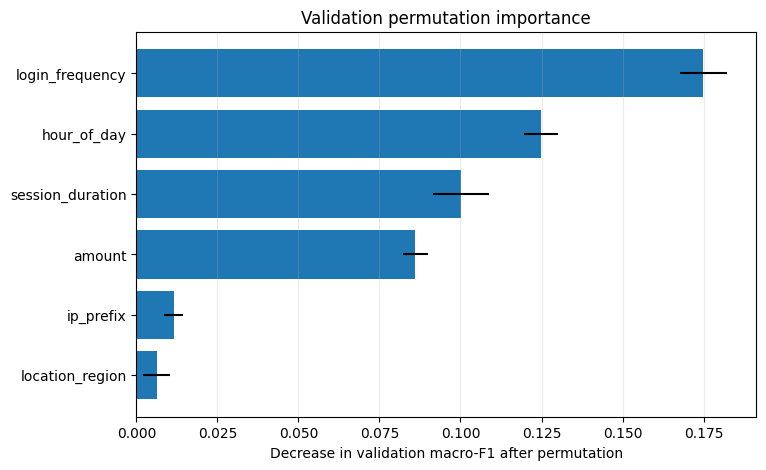

In [27]:
perm = permutation_importance(
    selected_model, X_val, y_val,
    scoring="f1_macro", n_repeats=10,
    random_state=RANDOM_STATE, n_jobs=-1
)
importance = pd.DataFrame({
    "feature": FEATURES,
    "importance_mean": perm.importances_mean,
    "importance_std": perm.importances_std
}).sort_values("importance_mean", ascending=False)

display(importance)
importance.to_csv(OUTPUT_DIR / "08_validation_permutation_importance.csv", index=False)

plt.figure(figsize=(8, 5))
plot_imp = importance.sort_values("importance_mean")
plt.barh(plot_imp["feature"], plot_imp["importance_mean"], xerr=plot_imp["importance_std"])
plt.xlabel("Decrease in validation macro-F1 after permutation")
plt.title("Validation permutation importance")
plt.grid(axis="x", alpha=0.25)
plt.show()

## 8. Optional SHAP explanations

SHAP is optional because installation and support vary by estimator and environment. The cell attempts a model-agnostic explanation on a small validation sample. If SHAP is unavailable or the estimator is unsupported, the notebook retains permutation importance as the primary explainability result.

SHAP version: 0.54.1


  0%|          | 0/250 [00:00<?, ?it/s]

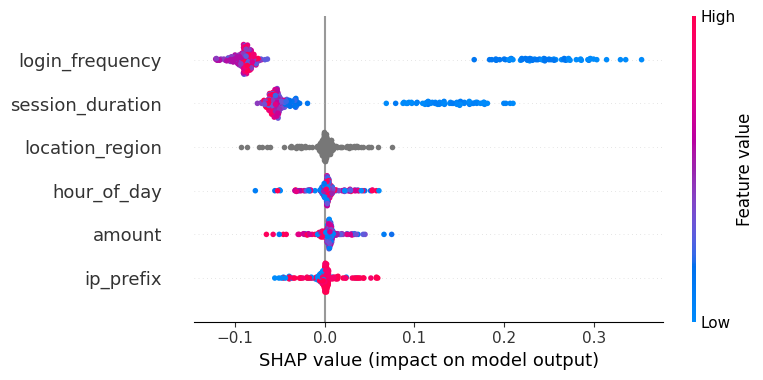

In [28]:
try:
    import shap
    print("SHAP version:", shap.__version__)
    # Use a small sample to keep runtime and memory manageable.
    X_explain = X_val.sample(min(250, len(X_val)), random_state=RANDOM_STATE)
    # Pipeline-agnostic KernelExplainer can be slow; limit background and samples.
    X_background = X_train.sample(min(40, len(X_train)), random_state=RANDOM_STATE)
    def high_risk_probability(raw_frame):
        return selected_model.predict_proba(
            pd.DataFrame(raw_frame, columns=FEATURES)
        )[:, classes.index(HIGH_RISK_LABEL)]
    explainer = shap.KernelExplainer(
        high_risk_probability, X_background.to_numpy()
    )
    shap_values = explainer.shap_values(X_explain.to_numpy(), nsamples=80)
    shap.summary_plot(shap_values, X_explain, show=True)
except Exception as exc:
    print("SHAP explanation skipped; permutation importance remains available.")
    print(type(exc).__name__ + ":", exc)

## 9. False-positive and false-negative review

This section reports counts and a small, privacy-conscious sample of test row positions and model scores. It deliberately does not display sender/receiver addresses or other identifiers. Use this analysis to understand error patterns, not to infer fraud intent from individual records.

In [29]:
error_review = test_df[["timestamp", "amount", "hour_of_day",
                        "login_frequency", "session_duration",
                        "location_region", "ip_prefix", TARGET]].copy()
error_review["predicted_class"] = test_pred
error_review["high_risk_probability"] = test_high_score
error_review["high_risk_alert"] = test_high_pred

false_negative_high = error_review[
    (error_review[TARGET] == HIGH_RISK_LABEL) &
    (error_review["high_risk_alert"] == 0)
]
false_positive_high = error_review[
    (error_review[TARGET] != HIGH_RISK_LABEL) &
    (error_review["high_risk_alert"] == 1)
]

print("High-risk false negatives:", len(false_negative_high))
print("High-risk false positives:", len(false_positive_high))
print("\nFalse-negative sample:")
display(false_negative_high.head(20))
print("\nFalse-positive sample:")
display(false_positive_high.head(20))

# Aggregated diagnostics, where sample sizes permit.
for label, subset in [
    ("false_negative_high", false_negative_high),
    ("false_positive_high", false_positive_high)
]:
    if len(subset):
        print("\n", label, "— numeric summary")
        display(subset[["amount", "hour_of_day", "login_frequency",
                        "session_duration", "high_risk_probability"]].describe())

High-risk false negatives: 8
High-risk false positives: 3957

False-negative sample:


,timestamp,amount,hour_of_day,login_frequency,session_duration,location_region,ip_prefix,anomaly,predicted_class,high_risk_probability,high_risk_alert
64932,2022-10-30 03:37:21,662.262108,3,1,22,Europe,10.00,high_risk,low_risk,0.101224,0
69491,2022-11-20 01:16:26,849.594358,1,2,31,North America,192.00,high_risk,moderate_risk,0.187246,0
69957,2022-11-22 03:33:34,1006.960048,3,2,33,Asia,10.00,high_risk,moderate_risk,0.218977,0
70564,2022-11-24 21:32:35,595.984515,21,1,21,South America,172.16,high_risk,low_risk,0.198561,0
75096,2022-12-16 03:31:12,680.652686,3,1,29,Africa,192.00,high_risk,low_risk,0.222677,0
76992,2022-12-24 14:56:30,640.533025,14,1,20,North America,10.00,high_risk,low_risk,0.170289,0
77847,2022-12-28 16:54:49,790.831237,16,2,39,Europe,192.00,high_risk,low_risk,0.220717,0
77958,2022-12-29 04:26:27,521.122801,4,1,25,Europe,10.00,high_risk,low_risk,0.141775,0



False-positive sample:


,timestamp,amount,hour_of_day,login_frequency,session_duration,location_region,ip_prefix,anomaly,predicted_class,high_risk_probability,high_risk_alert
62881,2022-10-20 17:53:57,636.822245,17,1,39,Africa,10.000,low_risk,high_risk,0.602623,1
62882,2022-10-20 17:56:43,787.224426,17,1,21,Europe,192.168,low_risk,low_risk,0.491006,1
62889,2022-10-20 18:46:37,509.906110,18,1,30,Europe,192.000,low_risk,high_risk,0.678118,1
62890,2022-10-20 18:49:10,527.972422,18,1,21,South America,192.168,low_risk,low_risk,0.481579,1
62891,2022-10-20 18:52:24,760.214531,18,1,36,Asia,172.160,low_risk,high_risk,0.743551,1
62901,2022-10-20 20:22:00,592.061139,20,2,36,Europe,192.000,low_risk,high_risk,0.521882,1
62902,2022-10-20 20:24:00,533.929372,20,1,27,South America,172.000,low_risk,low_risk,0.478784,1
62907,2022-10-20 21:07:27,759.649427,21,2,26,North America,192.000,low_risk,high_risk,0.689076,1
62909,2022-10-20 21:16:10,414.242533,21,2,22,Asia,172.160,low_risk,high_risk,0.724575,1
62914,2022-10-20 21:40:39,548.715383,21,2,35,Europe,10.000,low_risk,high_risk,0.589487,1



 false_negative_high — numeric summary


,amount,hour_of_day,login_frequency,session_duration,high_risk_probability
count,8.000000,8.00000,8.000000,8.000000,8.000000
mean,718.492597,8.12500,1.375000,27.500000,0.182683
std,155.961767,7.64269,0.517549,6.676184,0.043258
min,521.122801,1.00000,1.000000,20.000000,0.101224
25%,629.395898,3.00000,1.000000,21.750000,0.163161
50%,671.457397,3.50000,1.000000,27.000000,0.192904
75%,805.522018,14.50000,2.000000,31.500000,0.219412
max,1006.960048,21.00000,2.000000,39.000000,0.222677



 false_positive_high — numeric summary


,amount,hour_of_day,login_frequency,session_duration,high_risk_probability
count,3957.000000,3957.000000,3957.00000,3957.000000,3957.000000
mean,506.445798,11.655547,1.51352,29.429618,0.531647
std,246.731695,6.936690,0.49988,5.765112,0.130512
min,0.010000,0.000000,1.00000,20.000000,0.223718
25%,332.808467,6.000000,1.00000,24.000000,0.438976
50%,501.368848,12.000000,2.00000,29.000000,0.529801
75%,674.813298,18.000000,2.00000,34.000000,0.622549
max,1304.555430,23.000000,2.00000,39.000000,0.922814


## 10. Baseline context and interpretation

Compare model accuracy with a naive always-majority-class baseline, but do not use accuracy alone for an imbalanced multiclass target. A model can have lower raw accuracy than the majority baseline while providing substantially better balanced accuracy and minority-class recall.

In [30]:
majority_label = y_train.value_counts().idxmax()
majority_pred = np.repeat(majority_label, len(y_test))
baseline = {
    "majority_class": majority_label,
    "majority_baseline_accuracy": accuracy_score(y_test, majority_pred),
    "majority_baseline_balanced_accuracy": balanced_accuracy_score(y_test, majority_pred),
    "selected_model_accuracy": accuracy_score(y_test, test_pred),
    "selected_model_balanced_accuracy": balanced_accuracy_score(y_test, test_pred),
    "selected_model_macro_f1": f1_score(y_test, test_pred, average="macro", zero_division=0)
}
display(pd.DataFrame([baseline]).T.rename(columns={0: "value"}))
pd.DataFrame([baseline]).to_csv(OUTPUT_DIR / "08_baseline_context.csv", index=False)

,value
majority_class,low_risk
majority_baseline_accuracy,0.810508
majority_baseline_balanced_accuracy,0.333333
selected_model_accuracy,0.761402
selected_model_balanced_accuracy,0.779197
selected_model_macro_f1,0.660103


## 11. Reproducibility metadata and exported outputs

All key metrics, thresholds, split boundaries, feature choices, source hash, and assumptions are recorded in JSON. Export the output directory as a ZIP for review.

In [31]:
import zipfile

metadata = {
    "notebook": "08_Advanced_Ensemble_Optimization_Cost_Sensitive_Learning_and_Explainability",
    "source_file": DATA_PATH.name,
    "source_sha256": sha256,
    "dataset_shape": list(df.shape),
    "target": TARGET,
    "target_interpretation": "Kaggle-provided risk label; not independently verified fraud ground truth",
    "features": FEATURES,
    "excluded_features": sorted(list(PROHIBITED)),
    "split": {
        "method": "chronological",
        "train_fraction": TRAIN_FRAC,
        "validation_fraction": VALIDATION_FRAC,
        "test_fraction": TEST_FRAC,
        "train_end_timestamp": str(train_df["timestamp"].max()),
        "validation_end_timestamp": str(val_df["timestamp"].max()),
        "test_start_timestamp": str(test_df["timestamp"].min())
    },
    "random_state": RANDOM_STATE,
    "candidate_models": list(models.keys()),
    "selection_rule": "max validation macro-F1; tie-break balanced accuracy, then argmax high-risk recall",
    "selected_model": selected_name,
    "threshold_selection": {
        "method": "validation-only one-vs-rest threshold search",
        "minimum_high_risk_recall": MIN_VALIDATION_HIGH_RISK_RECALL,
        "selected_threshold": chosen_threshold,
        "recall_constraint_met": bool(constraint_met),
        "false_negative_cost_assumption": COST_FALSE_NEGATIVE_HIGH,
        "false_positive_cost_assumption": COST_FALSE_POSITIVE_HIGH
    },
    "test_metrics": test_summary,
    "test_high_risk_screening_metrics": screen_metrics,
    "limitations": [
        "Feature independence from the dataset label-generation process is not established.",
        "Permutation and SHAP importance are not causal explanations.",
        "Illustrative cost weights require stakeholder validation.",
        "One chronological holdout does not establish deployment performance.",
        "No automatic transaction-blocking recommendation is made."
    ]
}
with open(OUTPUT_DIR / "08_reproducibility_metadata.json", "w") as f:
    json.dump(metadata, f, indent=2, default=str)

print("Saved outputs:")
for p in sorted(OUTPUT_DIR.iterdir()):
    print(p.name, p.stat().st_size, "bytes")

zip_path = Path("/content/08_notebook_outputs.zip")
with zipfile.ZipFile(zip_path, "w", zipfile.ZIP_DEFLATED) as z:
    for p in OUTPUT_DIR.iterdir():
        z.write(p, arcname=f"ecips_notebook08_outputs/{p.name}")
print("Created:", zip_path)

Saved outputs:
08_baseline_context.csv 263 bytes
08_final_test_classification_report.csv 499 bytes
08_final_test_confusion_matrix.csv 154 bytes
08_final_test_high_risk_confusion_matrix.csv 92 bytes
08_final_test_high_risk_screening_metrics.csv 228 bytes
08_final_test_summary.csv 304 bytes
08_reproducibility_metadata.json 2819 bytes
08_validation_high_risk_threshold_curve.csv 24647 bytes
08_validation_model_comparison.csv 1283 bytes
08_validation_permutation_importance.csv 364 bytes
Created: /content/08_notebook_outputs.zip


## 12. Research conclusions checklist

Complete this checklist after execution:

1. Does the selected model satisfy the validation high-risk recall constraint?
2. What precision and false-positive volume accompany the selected threshold on the untouched test set?
3. Does cost-sensitive screening improve the chosen operating objective compared with the argmax classifier?
4. Are validation permutation-importance rankings stable and plausible, given the known provenance limitations?
5. Do errors cluster by time, region, amount, or behavioral variables?
6. Are the assumed false-negative and false-positive costs defensible with domain stakeholders?
7. Can the results be described only as prediction of the supplied risk labels, rather than verified fraud detection?

**Do not report the highest accuracy as the sole winner.** Discuss macro-F1, balanced accuracy, high-risk precision/recall, alert volume, and the limitations of the labels together.